# Step 02: Target-Relative Centering, Windowing & Representation Extraction

Demonstrates the feature preparation pipeline:
1. **Target-Relative Spatial Centering**: Strips absolute X, Y position while preserving height $z$.
2. **Sliding Window Extraction & Resampling**: $10 \text{ frames} \times 32 \text{ points} = 320 \text{ points/window}$.
3. **Multi-Modal Feature Representations**:
   - **Rep 1**: Micro-Doppler Time Map (`3, 32, 32` for ResNet-18)
   - **Rep 2**: 2D Orthogonal Projections (`3, 32, 32` for ResNet-18)
   - **Rep 3**: Geometric Native 3D Point Tensor (`5, 320` for PointNet++)


In [1]:
# Cell 1: System Imports & Setup
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path
root_dir = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
if str(root_dir) not in sys.path: sys.path.insert(0, str(root_dir))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.dataset_parser import get_all_recording_files, load_recording_df
from src.transforms import (
    extract_raw_windows_from_df,
    transform_rep1_doppler_time,
    transform_rep2_orthogonal_projections,
    transform_rep3_pointnet
)

sns.set_theme(style="whitegrid")
all_files = get_all_recording_files()
sample_fall = next(f for f in all_files if "back" in f.name.lower() or "fall" in f.parent.name.lower())
df_clean = load_recording_df(sample_fall)
print(f"Loaded Sample Fall Recording: {sample_fall.name}")


Loaded Sample Fall Recording: Areeb_back_1.csv


In [2]:
# Cell 2: Extract Sliding Windows (10 Frames, Stride 5, N=32 Points)
raw_windows = extract_raw_windows_from_df(df_clean, window_size_frames=10, stride=5)
raw_windows = np.array(raw_windows, dtype=np.float32)
print(f"Extracted {len(raw_windows)} sliding windows of shape {raw_windows.shape} (N, T=10, P=32, C=4)")


Extracted 3 sliding windows of shape (3, 10, 32, 4) (N, T=10, P=32, C=4)


Representation 1 Output Tensor Shape: (3, 3, 32, 32) (N, 3, 32, 32)


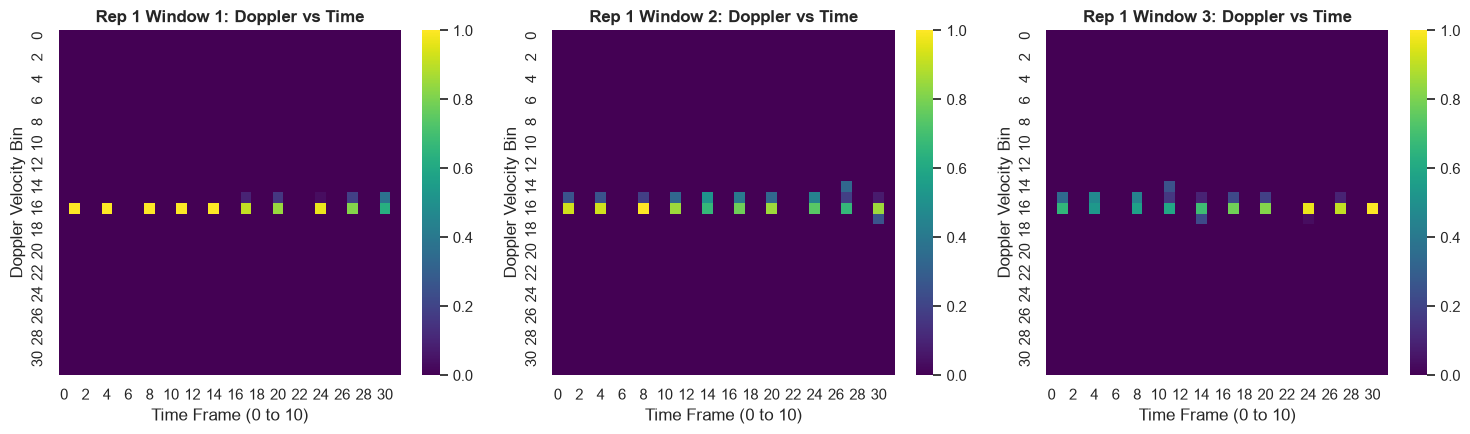

In [3]:
# Cell 3: Visualize Representation 1 — Micro-Doppler Velocity-Time Spectrogram (ResNet-18)
rep1_tensors = transform_rep1_doppler_time(raw_windows)
print(f"Representation 1 Output Tensor Shape: {rep1_tensors.shape} (N, 3, 32, 32)")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), dpi=100)
for i in range(min(3, len(rep1_tensors))):
    img_ch0 = rep1_tensors[i, 0]  # (32, 32)
    sns.heatmap(img_ch0, cmap="viridis", ax=axes[i], cbar=True)
    axes[i].set_title(f"Rep 1 Window {i+1}: Doppler vs Time", fontweight="bold")
    axes[i].set_xlabel("Time Frame (0 to 10)")
    axes[i].set_ylabel("Doppler Velocity Bin")

plt.tight_layout()
plt.show()


Representation 2 Output Tensor Shape: (3, 3, 32, 32) (N, 3, 32, 32)


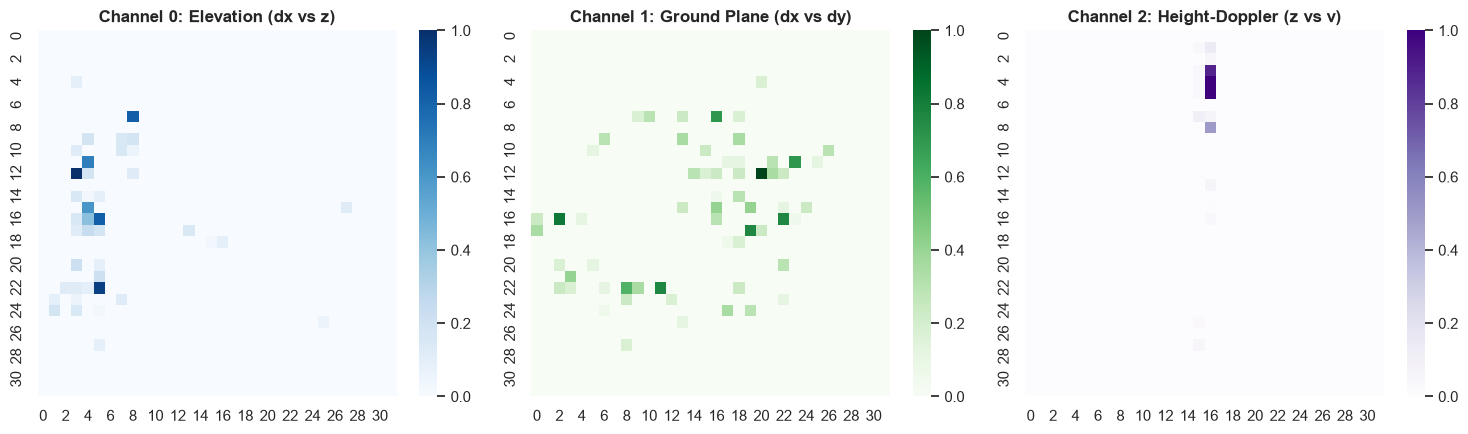

In [4]:
# Cell 4: Visualize Representation 2 — 2D Orthogonal Spatial Projections (ResNet-18)
rep2_tensors = transform_rep2_orthogonal_projections(raw_windows)
print(f"Representation 2 Output Tensor Shape: {rep2_tensors.shape} (N, 3, 32, 32)")

sample_win_idx = 0
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), dpi=100)
channel_titles = ["Channel 0: Elevation (dx vs z)", "Channel 1: Ground Plane (dx vs dy)", "Channel 2: Height-Doppler (z vs v)"]
cmaps = ["Blues", "Greens", "Purples"]

for ch in range(3):
    sns.heatmap(rep2_tensors[sample_win_idx, ch], cmap=cmaps[ch], ax=axes[ch], cbar=True)
    axes[ch].set_title(channel_titles[ch], fontweight="bold")

plt.tight_layout()
plt.show()


Representation 3 Output Tensor Shape: (3, 5, 320) (N, 5, 320)


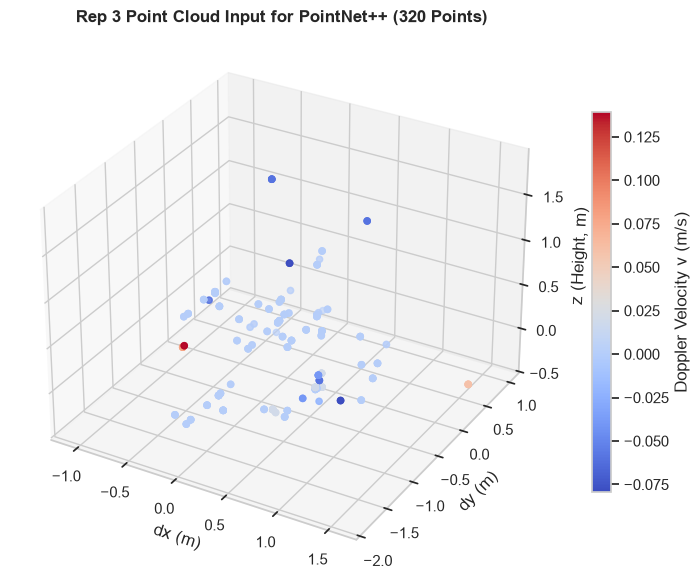

In [5]:
# Cell 5: Visualize Representation 3 — Geometric Native 3D Point Tensor (PointNet++)
rep3_tensors = transform_rep3_pointnet(raw_windows)
print(f"Representation 3 Output Tensor Shape: {rep3_tensors.shape} (N, 5, 320)")

sample_pts = rep3_tensors[0].T  # (320, 5) with [dx, dy, z, v, dz]
fig = plt.figure(figsize=(8, 6), dpi=100)
ax = fig.add_subplot(111, projection="3d")
sc = ax.scatter(sample_pts[:, 0], sample_pts[:, 1], sample_pts[:, 2], c=sample_pts[:, 3], cmap="coolwarm", s=20)
ax.set_title("Rep 3 Point Cloud Input for PointNet++ (320 Points)", fontweight="bold")
ax.set_xlabel("dx (m)")
ax.set_ylabel("dy (m)")
ax.set_zlabel("z (Height, m)")
fig.colorbar(sc, ax=ax, shrink=0.7, label="Doppler Velocity v (m/s)")

plt.tight_layout()
plt.show()
